In [1]:
import os
from typing import List
from dotenv import load_dotenv
from pydantic import BaseModel, Field

from langchain.chat_models import init_chat_model
from langchain_core.documents import Document                    # langchain.schema ki jagah
from langchain_huggingface import HuggingFaceEmbeddings          # OpenAIEmbeddings ki jagah
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS               # langchain.vectorstores ki jagah
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, START, END


C:\Users\Adit Sharma\AppData\Local\Temp\ipykernel_18644\2105620218.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


In [2]:
load_dotenv()      # original mein yeh call hi nahi tha
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")

llm = init_chat_model("groq:openai/gpt-oss-20b", temperature=0)
llm


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000021EC2E292B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000021EC2E29FD0>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
docs = TextLoader("research_notes.txt", encoding="utf-8").load()
chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)

embedding = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = FAISS.from_documents(chunks, embedding)
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})   

print(len(chunks), "chunks")
retriever.invoke("transformer variants")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

5 chunks


[Document(id='b401059a-49e1-4884-8c49-741d6b18307d', metadata={'source': 'research_notes.txt'}, page_content="Experiment 14: Transformer variants for long documents\nWe compared a standard Transformer, Longformer and a Mixture-of-Experts (MoE) Transformer on our 8k-token contract summarisation dataset.\nLongformer's sliding-window attention reduced memory use by 45 percent compared to full attention, with only a 1.2 point drop in ROUGE-L.\nThe MoE variant (8 experts, top-2 routing) gave the best ROUGE-L score (+2.1 over baseline) but training was unstable without a load-balancing loss."),
 Document(id='646f7727-8f28-4e49-8d06-fa44aa41d03b', metadata={'source': 'research_notes.txt'}, page_content='Conclusion: use Longformer for cost-sensitive workloads and MoE when quality matters most.'),
 Document(id='37bff000-d924-49f1-8c47-2c3b948aaceb', metadata={'source': 'research_notes.txt'}, page_content='Internal Research Notes - Applied ML Team')]

In [5]:
class RAGCoTState(BaseModel):
    question: str
    sub_steps: List[str] = []
    retrieved_docs: List[Document] = []
    answer: str = ""


In [6]:
class Plan(BaseModel):
    """Reasoning steps for answering the question."""
    steps: List[str] = Field(description="2-3 short sub-questions, each searchable on its own")

planner_llm = llm.with_structured_output(Plan)

def plan_steps(state: RAGCoTState):
    prompt = (
        "Break the question into 2-3 reasoning steps. "
        "Write each step as a short sub-question that can be searched on its own.\n\n"
        f"Question: {state.question}"
    )
    plan = planner_llm.invoke(prompt)
    print("🪜 Plan:", plan.steps)
    return {"sub_steps": plan.steps}          


In [7]:
def retrieve_per_step(state: RAGCoTState):
    all_docs, seen = [], set()
    for sub in state.sub_steps:
        for doc in retriever.invoke(sub):
            if doc.page_content not in seen:      
                seen.add(doc.page_content)
                all_docs.append(doc)
    print(f"📚 {len(all_docs)} unique chunks retrieved")
    return {"retrieved_docs": all_docs}


In [8]:
def generate_answer(state: RAGCoTState):
    context = "\n\n".join(doc.page_content for doc in state.retrieved_docs)
    steps = "\n".join(f"- {s}" for s in state.sub_steps)
    prompt = f"""You are answering a complex question using reasoning and retrieved documents.

Question: {state.question}

Reasoning steps:
{steps}

Relevant information:
{context}

Work through the steps, then give a well-reasoned final answer using only the information above."""
    return {"answer": llm.invoke(prompt).content.strip()}


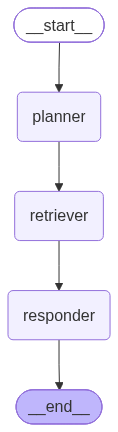

In [9]:
builder = StateGraph(RAGCoTState)
builder.add_node("planner", plan_steps)
builder.add_node("retriever", retrieve_per_step)
builder.add_node("responder", generate_answer)

builder.add_edge(START, "planner")         
builder.add_edge("planner", "retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", END)

graph = builder.compile()
graph


In [10]:
query = "What are the additional experiments in Transformer evaluation?"
final = graph.invoke(RAGCoTState(question=query))

print("\n🪜 Reasoning Steps:", final["sub_steps"])
print("\n✅ Final Answer:\n", final["answer"])


🪜 Plan: ['What are the standard evaluation experiments for Transformers?', 'What additional experiments are commonly performed in Transformer evaluation?', 'Which specific additional experiments are included in Transformer evaluation?']
📚 4 unique chunks retrieved

🪜 Reasoning Steps: ['What are the standard evaluation experiments for Transformers?', 'What additional experiments are commonly performed in Transformer evaluation?', 'Which specific additional experiments are included in Transformer evaluation?']

✅ Final Answer:
 **Additional experiments performed in the Transformer evaluation**

| # | Experiment | Focus | Key Findings |
|---|------------|-------|--------------|
| **14** | **Transformer variants for long documents** | Comparison of a vanilla Transformer, Longformer, and a Mixture‑of‑Experts (MoE) Transformer on an 8 k‑token contract‑summarisation dataset. | • Longformer’s sliding‑window attention cut memory usage by **45 %** relative to full‑attention, with only a **1.2‑po